# WoE, IV and log-odds plots

**Aim:** for each feature, bin it, compute the Weight of Evidence (WoE) of each bin and the feature's Information Value (IV), and plot the log-odds of default by bin.

Everything here is computed on the train years only (2007-2014), so the test year can't influence the bins. Missing values get their own bin.

**Definitions**
- Default rate of a bin: defaults / loans in the bin.
- Log-odds of default: ln(defaults / non-defaults) in the bin.
- WoE: ln(share of all non-defaults in the bin / share of all defaults in the bin). Positive means lower risk than average.
- IV: sum over bins of (share of non-defaults − share of defaults) × WoE. It measures how well the feature separates defaulters from non-defaulters.

In [25]:
import sys
sys.path.insert(0, "../src")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import credit_risk.data_prep as dp

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 250)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
# train years only; test is not used in this notebook
train = pd.read_parquet("../data/processed/train.parquet")
print(train.shape)   # expect (393276, 41)

(393276, 41)


In [27]:
def bin_table(df, col, n_bins=10, min_loans=500):
    x, y = df[col].copy(), df["default"]
    numeric = pd.api.types.is_numeric_dtype(x)

    # a missing group too small to trust is treated as a typical loan
    if numeric and x.isnull().sum() < min_loans:
        x = x.fillna(x.median())

    if numeric and x.nunique() > n_bins:
        bins = pd.qcut(x, q=n_bins, duplicates="drop")        # equal-sized bins
        bins = bins.cat.add_categories("missing").fillna("missing")
    elif numeric:
        # few distinct values: merge rare high values into one "or more" bin
        counts = x.value_counts()
        cap = counts[counts >= min_loans].index.max()
        bins = x.clip(upper=cap).astype("object").fillna("missing")
    else:
        # categories: rare ones go into one "rare" bin
        counts = x.value_counts()
        rare = counts[counts < min_loans].index
        bins = x.where(~x.isin(rare), "rare").astype("object").fillna("missing")

    t = y.groupby(bins, observed=True).agg(loans="count", defaults="sum")
    t["non_defaults"] = t["loans"] - t["defaults"]
    t["default_rate"] = t["defaults"] / t["loans"]
    t["log_odds"] = np.log(t["defaults"] / t["non_defaults"])

    share_good = t["non_defaults"] / t["non_defaults"].sum()
    share_bad = t["defaults"] / t["defaults"].sum()
    t["woe"] = np.log(share_good / share_bad)
    t["iv"] = (share_good - share_bad) * t["woe"]
    return t.round(4)

In [28]:
t = bin_table(train, "int_rate")
print("IV:", round(t["iv"].sum(), 3))
t

IV: 0.336


,loans,defaults,non_defaults,default_rate,log_odds,woe,iv
int_rate,,,,,,,
"(5.419, 7.69]",42363,1863,40500,0.0440,-3.0791,1.3330,0.1187
"(7.69, 9.17]",37188,2742,34446,0.0737,-2.5307,0.7845,0.0439
"(9.17, 10.99]",45266,4365,40901,0.0964,-2.2375,0.4914,0.0233
"(10.99, 12.12]",39618,4385,35233,0.1107,-2.0838,0.3376,0.0102
"(12.12, 13.05]",32252,4427,27825,0.1373,-1.8382,0.0920,0.0007
"(13.05, 14.09]",40223,6132,34091,0.1525,-1.7155,-0.0307,0.0001
"(14.09, 15.31]",43220,7355,35865,0.1702,-1.5844,-0.1618,0.0030
"(15.31, 16.78]",35126,7187,27939,0.2046,-1.3577,-0.3884,0.0154
"(16.78, 18.99]",38767,8714,30053,0.2248,-1.2380,-0.5081,0.0302


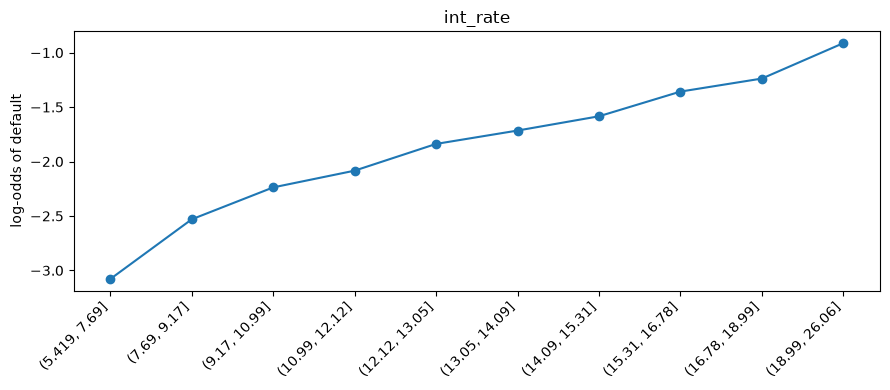

In [29]:
# log-odds of default by bin
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(len(t)), t["log_odds"], marker="o")
ax.set_xticks(range(len(t)))
ax.set_xticklabels(t.index.astype(str), rotation=45, ha="right")
ax.set_ylabel("log-odds of default")
ax.set_title("int_rate")
plt.tight_layout()
plt.show()

In [30]:
iv_rows = []
for col in dp.MODEL_FEATURES:
    t= bin_table(train, col)
    iv_rows.append({"feature": col, "iv": t["iv"].sum(),"n_bins": len(t) })


iv_table = pd.DataFrame(iv_rows).sort_values("iv", ascending=False).reset_index(drop=True)
iv_table.round(4)

,feature,iv,n_bins
0,sub_grade,0.3596,32
1,int_rate,0.3362,10
2,grade,0.3283,7
3,fico_range_low,0.1111,10
4,fico_range_high,0.1111,10
5,term,0.0922,2
6,annual_inc,0.0527,10
7,dti,0.0422,10
8,revol_util,0.0312,10
9,verification_status,0.0279,3


In [31]:
# features whose IV came out infinite
inf_features = iv_table.loc[np.isinf(iv_table["iv"]), "feature"]

# bins with no defaults or no good loans
problems = []
for col in inf_features:
    t = bin_table(train, col)
    bad = t[(t["defaults"] == 0) | (t["non_defaults"] == 0)]
    for b, row in bad.iterrows():
        problems.append({"feature": col, "bin": str(b), "loans": row["loans"], "defaults": row["defaults"]})

pd.DataFrame(problems)

""


In [32]:
def plot_feature(df, col):
    t = bin_table(df, col)
    iv = t["iv"].sum()
    pos = range(len(t))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.5))
    ax1.plot(pos, t["log_odds"], marker="o")      # left: log-odds of default by bin
    ax1.set_ylabel("log-odds of default")
    ax2.bar(pos, t["woe"])                        # right: WoE by bin, 0 = average
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.set_ylabel("WoE")

    for ax in (ax1, ax2):
        ax.set_xticks(pos)
        ax.set_xticklabels(t.index.astype(str), rotation=45, ha="right")

    fig.suptitle(f"{col}   IV = {iv:.3f}")
    plt.tight_layout()
    plt.show()

['sub_grade', 'grade', 'fico_range_low', 'term', 'annual_inc', 'dti', 'revol_util', 'verification_status', 'purpose', 'inq_last_6mths', 'home_ownership', 'credit_history_years', 'addr_state', 'emp_length', 'installment', 'loan_amnt', 'revol_bal', 'total_acc', 'pub_rec_bankruptcies', 'mths_since_last_delinq', 'open_acc', 'delinq_2yrs', 'collections_12_mths_ex_med', 'pub_rec', 'application_type', 'acc_now_delinq', 'chargeoff_within_12_mths', 'delinq_amnt', 'tax_liens']


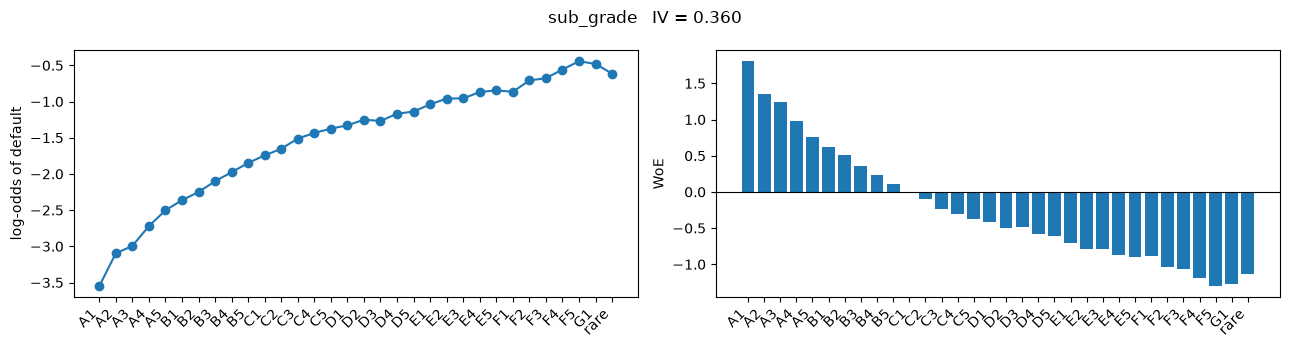

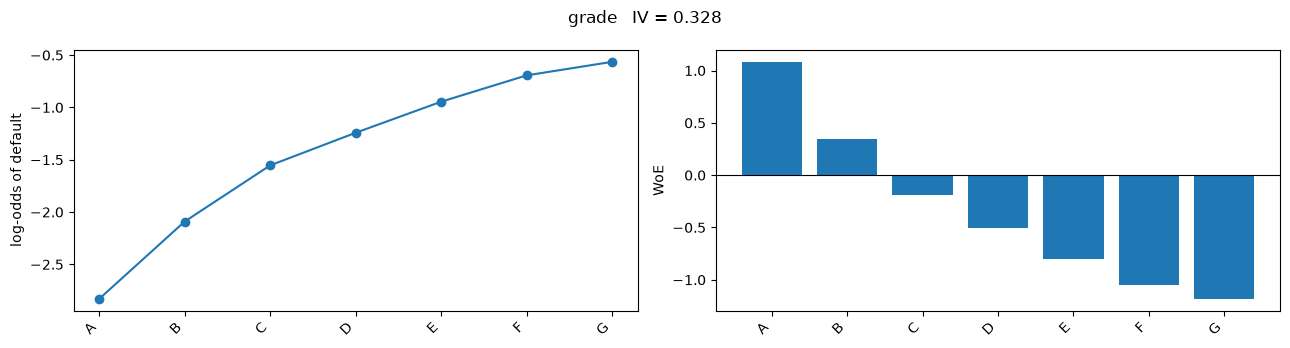

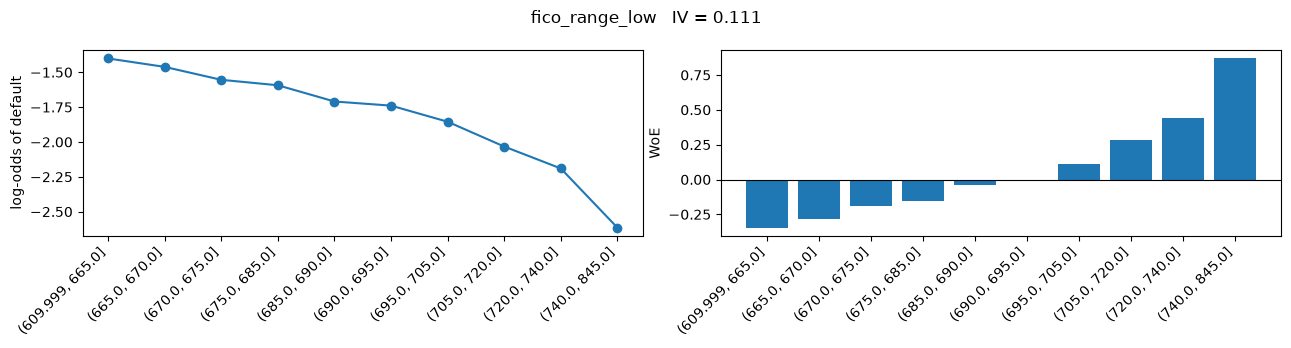

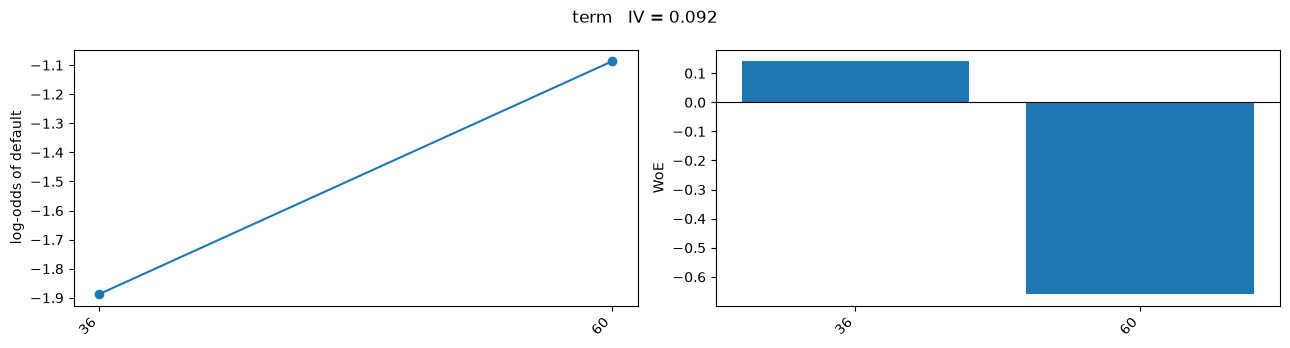

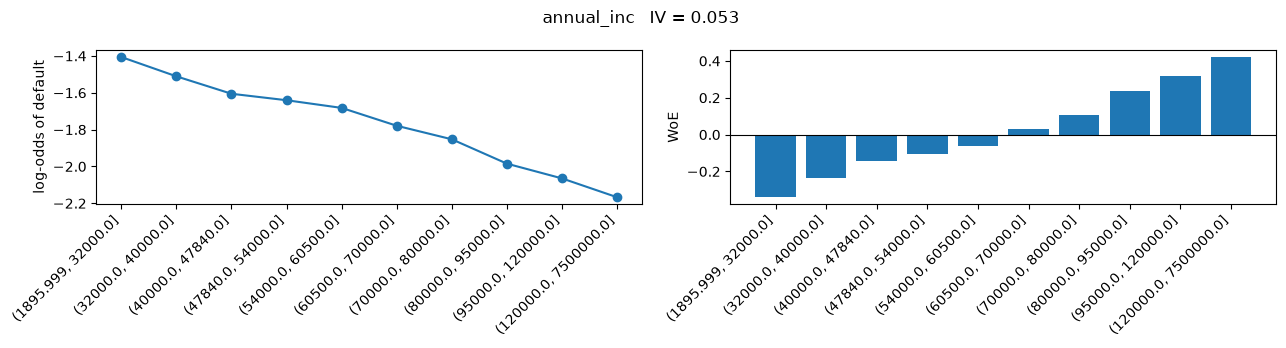

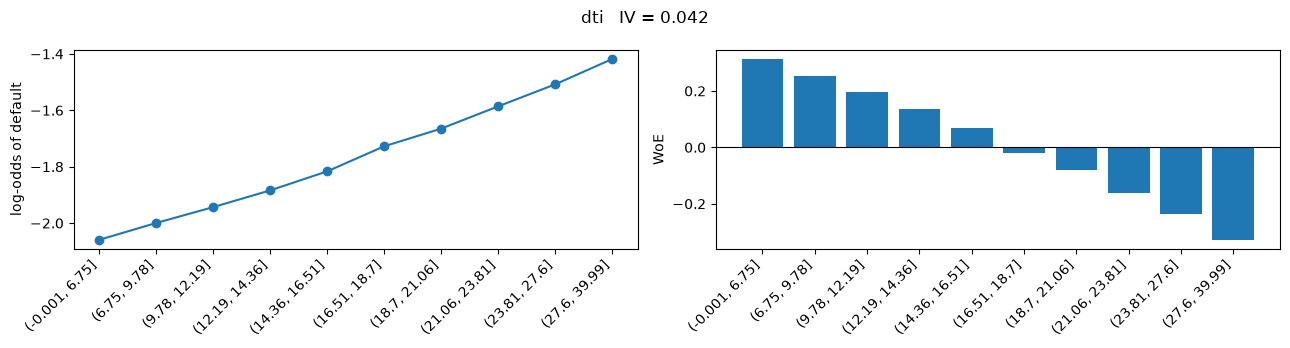

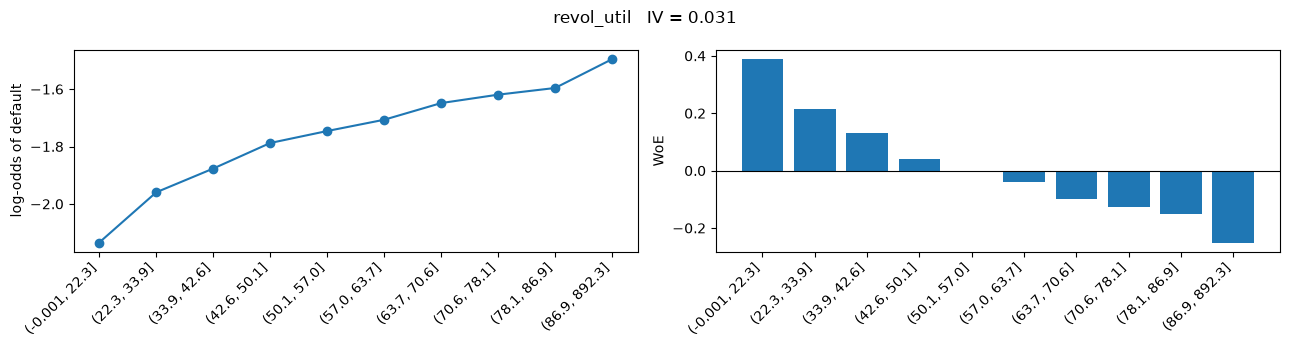

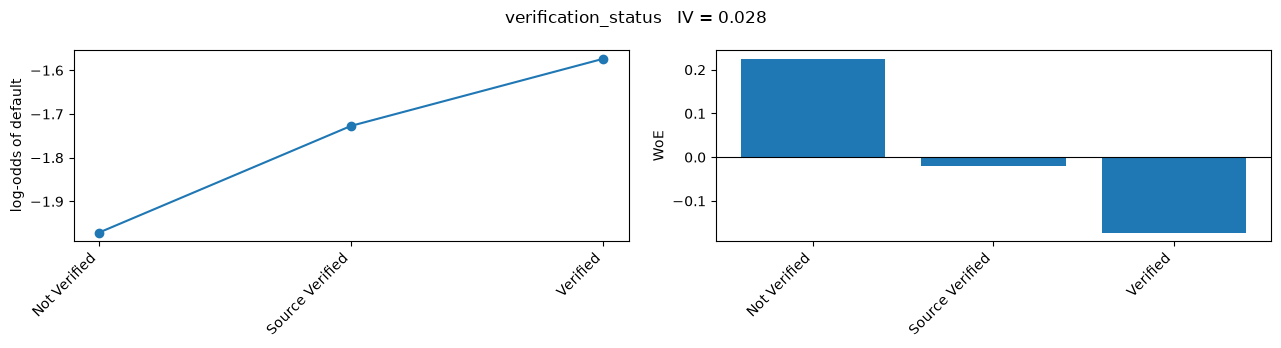

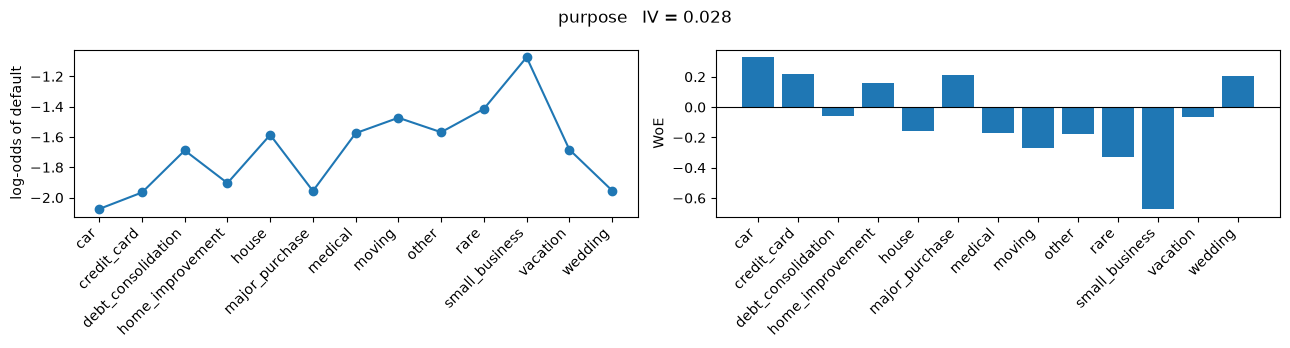

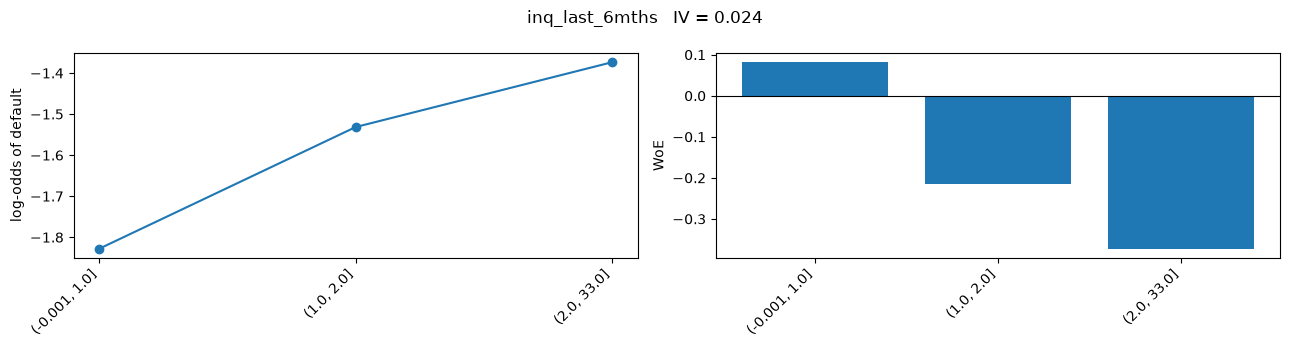

In [33]:
# features by IV, leaving out int_rate (already plotted) and fico_range_high (same as low)
ranked = [c for c in iv_table["feature"] if c not in ("int_rate", "fico_range_high")]
print(ranked)

for col in ranked[:10]:      # sub_grade, grade, fico_range_low, term
    plot_feature(train, col)

In [34]:
def plot_feature(df, col):
    t = bin_table(df, col)
    iv = t["iv"].sum()

    # new: categories have no natural order, so sort them from safest to riskiest
    # grade and sub_grade are excluded: A to G is already their order, and sorting would hide any break in it
    if not pd.api.types.is_numeric_dtype(df[col]) and col not in ("grade", "sub_grade"):
        t = t.sort_values("woe", ascending=False)

    pos = range(len(t))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.5))
    ax1.plot(pos, t["log_odds"], marker="o")      # left: log-odds of default by bin
    ax1.set_ylabel("log-odds of default")
    ax2.bar(pos, t["woe"])                        # right: WoE by bin, 0 = average
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.set_ylabel("WoE")

    for ax in (ax1, ax2):
        ax.set_xticks(pos)
        ax.set_xticklabels(t.index.astype(str), rotation=45, ha="right")

    fig.suptitle(f"{col}   IV = {iv:.3f}")
    plt.tight_layout()
    plt.show()

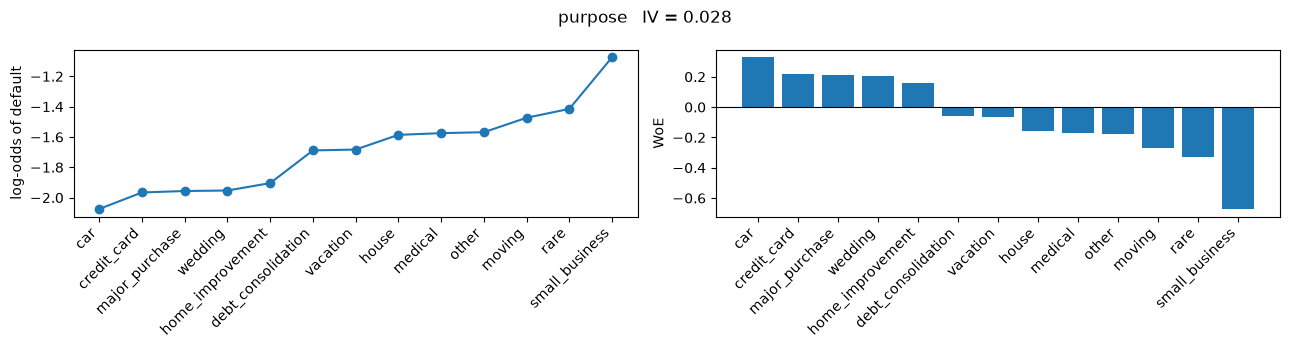

In [35]:
plot_feature(train, "purpose")

In [36]:
# share of each verification status within each grade
pd.crosstab(train["grade"], train["verification_status"], normalize="index").round(3)

verification_status,Not Verified,Source Verified,Verified
grade,,,
A,0.443,0.303,0.254
B,0.401,0.282,0.318
C,0.310,0.292,0.399
D,0.286,0.285,0.429
E,0.173,0.279,0.547
F,0.118,0.242,0.640
G,0.106,0.231,0.663


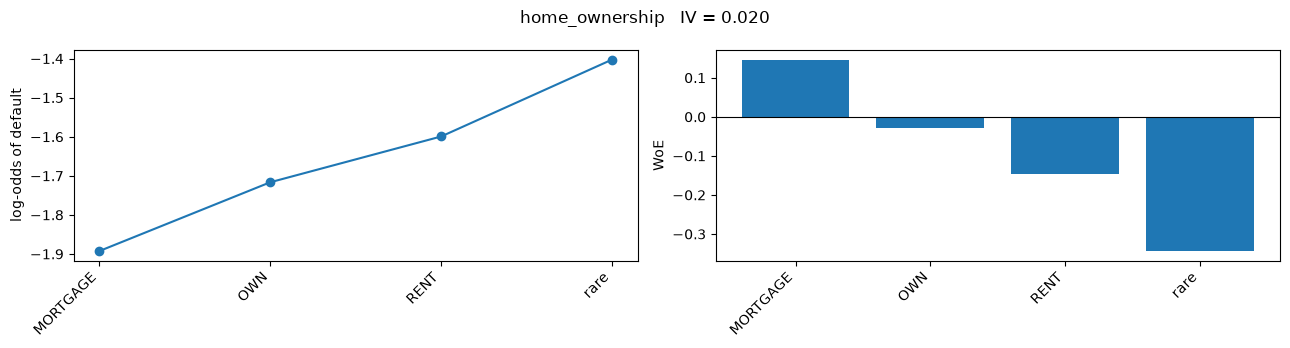

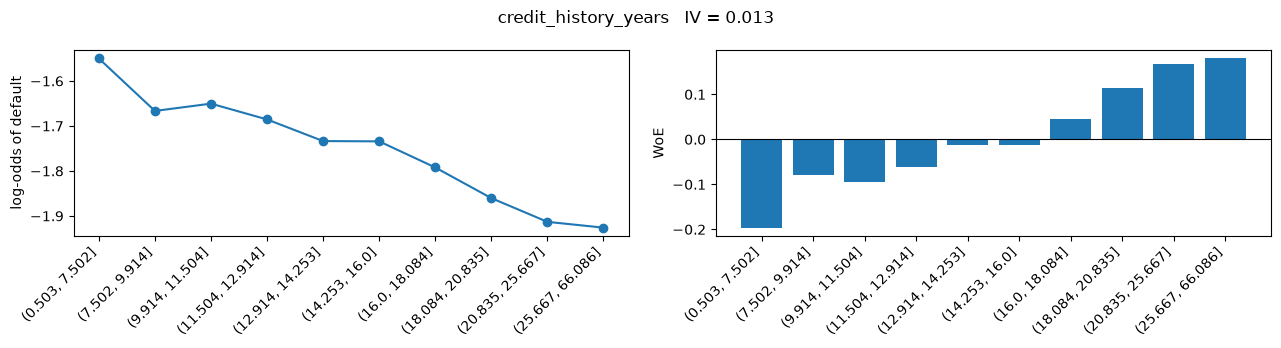

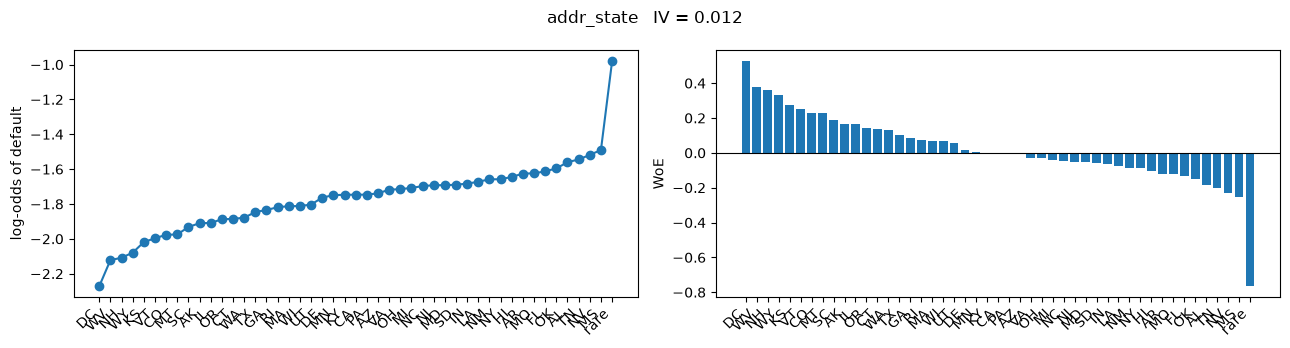

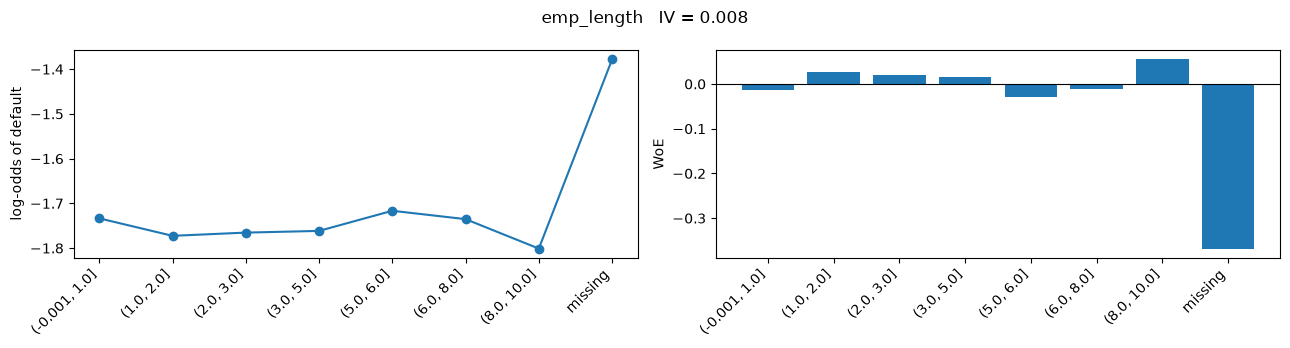

In [37]:
for col in ranked[10:14]:      # home_ownership, credit_history_years, addr_state, emp_length
    plot_feature(train, col)

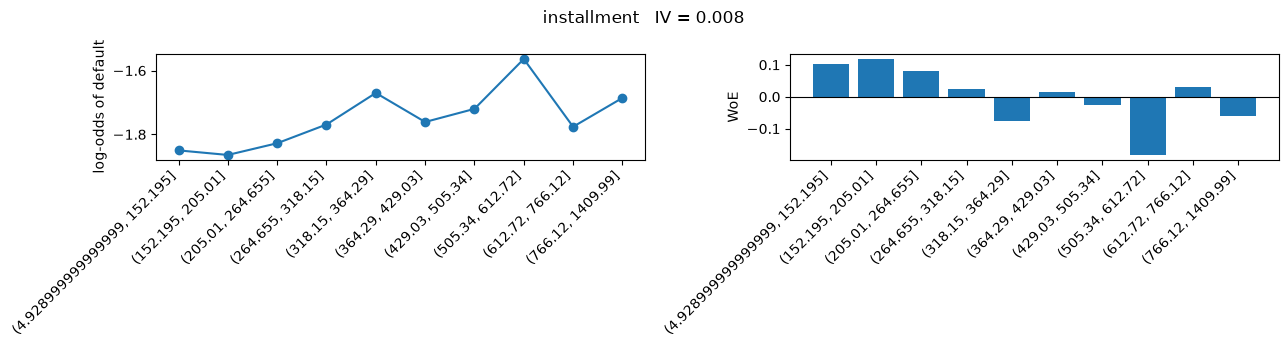

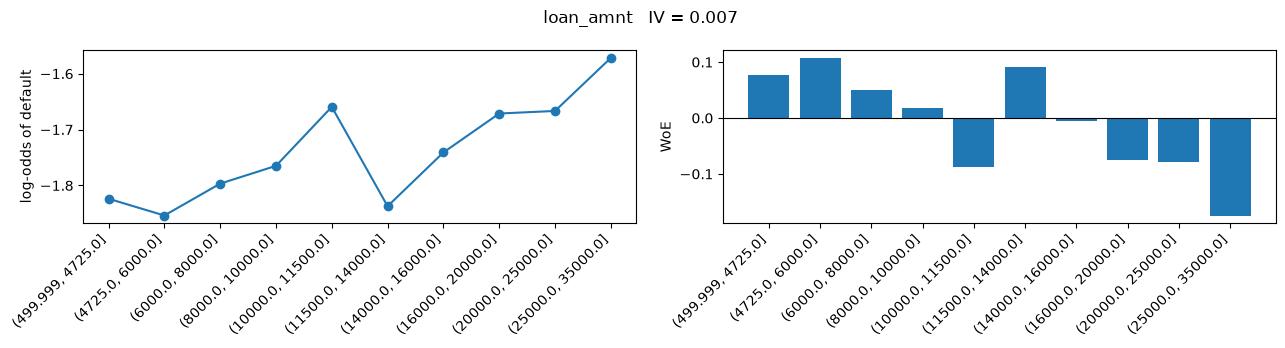

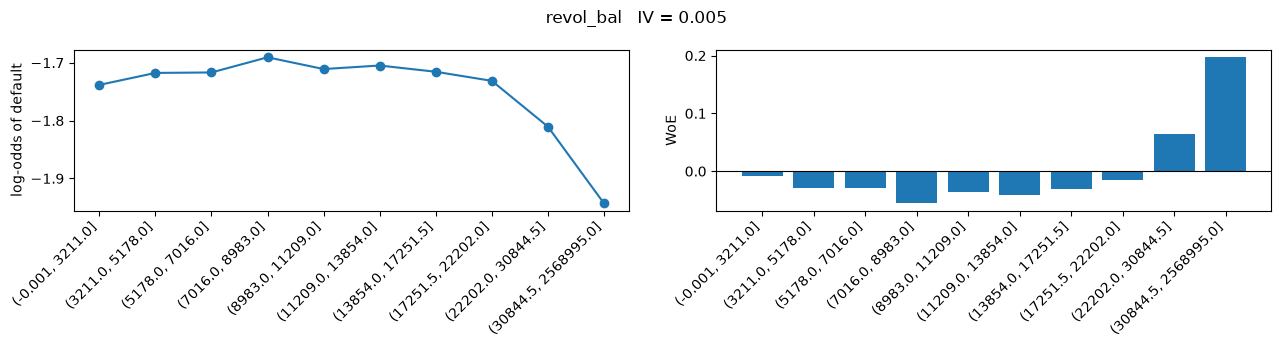

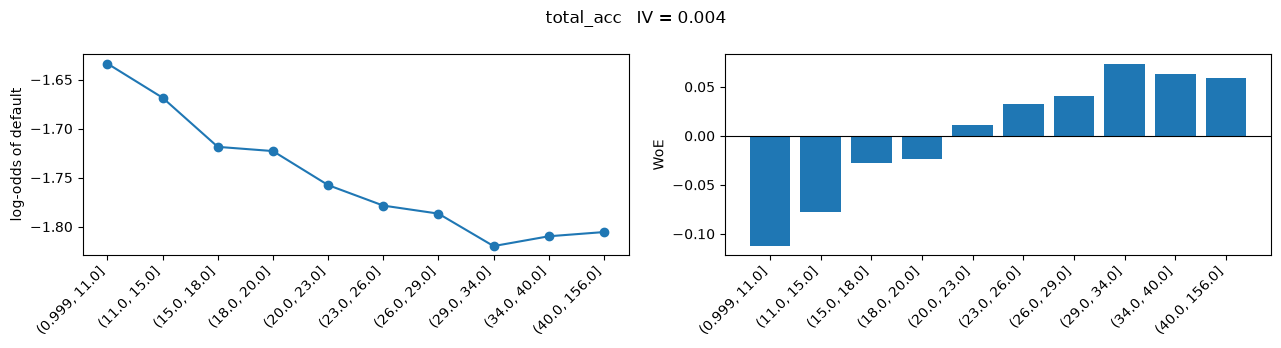

In [38]:
for col in ranked[14:18]:      # home_ownership, credit_history_years, addr_state, emp_length
    plot_feature(train, col)

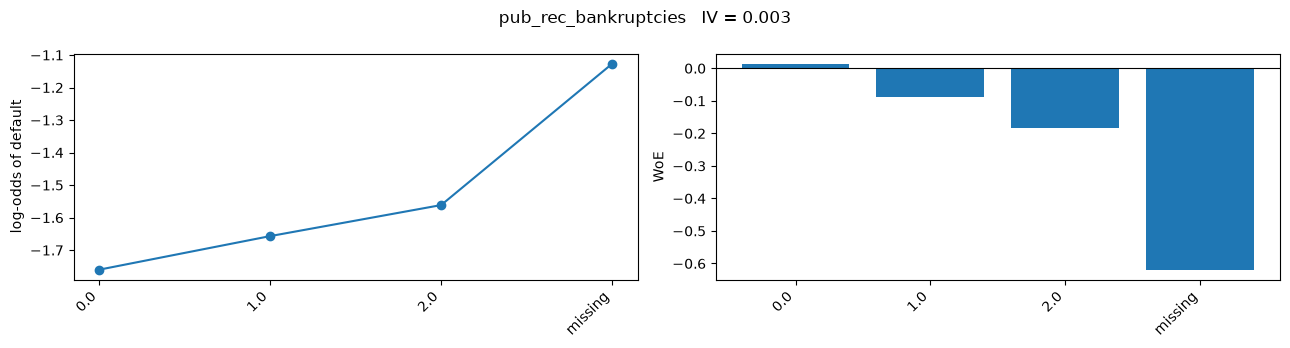

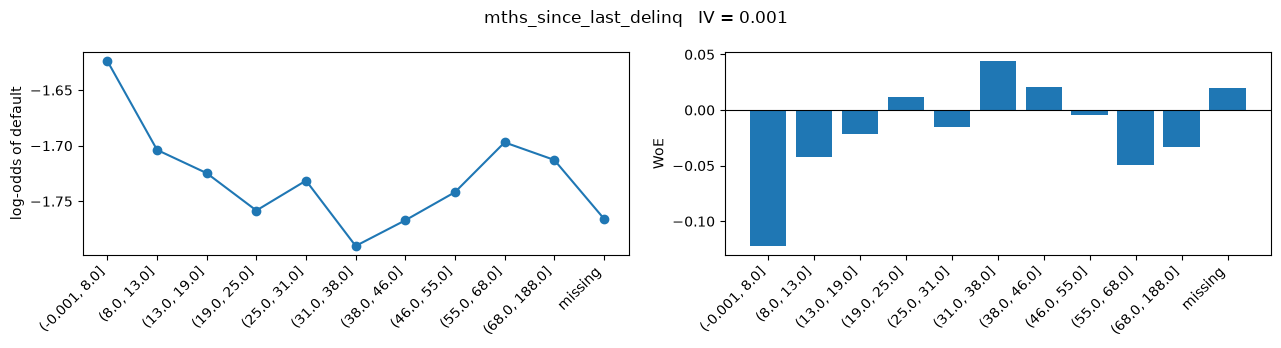

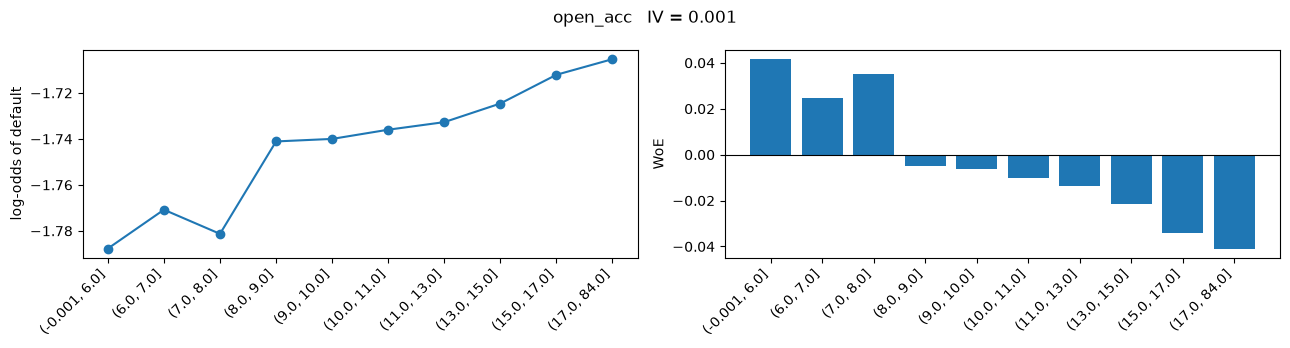

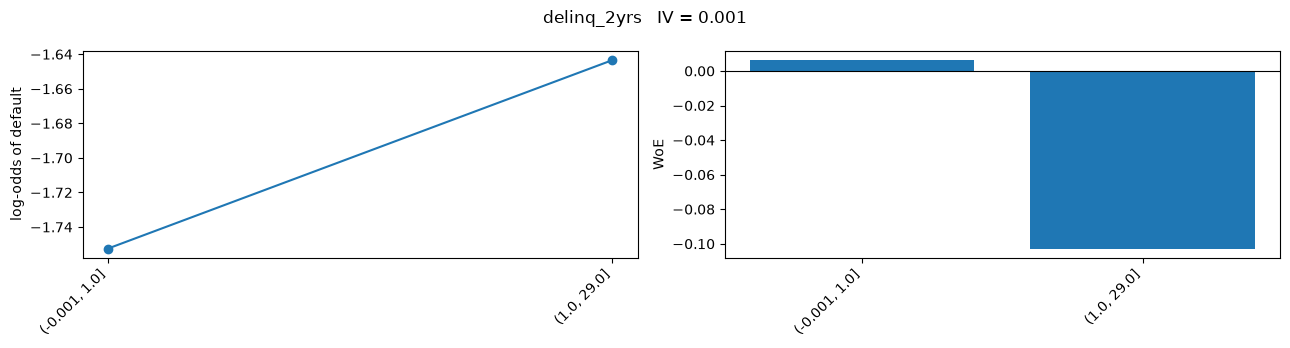

In [39]:
for col in ranked[18:22]:      # home_ownership, credit_history_years, addr_state, emp_length
    plot_feature(train, col)

In [40]:
# default rate by verification status, within each grade
train.groupby(["grade", "verification_status"])["default"].mean().unstack().round(3)

verification_status,Not Verified,Source Verified,Verified
grade,,,
A,0.053,0.059,0.058
B,0.106,0.112,0.114
C,0.162,0.179,0.181
D,0.198,0.234,0.235
E,0.243,0.289,0.287
F,0.275,0.343,0.340
G,0.363,0.353,0.366


In [41]:
  train.groupby(["issue_year", train["emp_length"].isnull()])["default"].mean().unstack().round(3)

emp_length,False,True
issue_year,,
2007,0.262,NaN
2008,0.207,NaN
2009,0.137,NaN
2010,0.137,0.255
2011,0.150,0.204
2012,0.161,0.197
2013,0.154,0.198
2014,0.133,0.202


In [42]:
  counts = train["addr_state"].value_counts()
  rare_states = counts[counts < 500].index
  in_rare = train["addr_state"].isin(rare_states)
  print(rare_states.tolist(), in_rare.sum(), round(train.loc[in_rare, "default"].mean(), 3))

['IA', 'NE', 'ID', 'ME'] 44 0.273


In [43]:
# size of the "rare" bin wherever bin_table created one
for col in ["addr_state", "sub_grade", "home_ownership", "purpose"]:
    t = bin_table(train, col)
    if "rare" in t.index:
        print(col, t.loc["rare", ["loans", "defaults", "default_rate"]].to_dict())

addr_state {'loans': 44.0, 'defaults': 12.0, 'default_rate': 0.2727}
sub_grade {'loans': 1145.0, 'defaults': 402.0, 'default_rate': 0.3511}
home_ownership {'loans': 233.0, 'defaults': 46.0, 'default_rate': 0.1974}
purpose {'loans': 752.0, 'defaults': 147.0, 'default_rate': 0.1955}


In [44]:
# nonzero split for features where almost every loan has one value
flat = ["collections_12_mths_ex_med", "pub_rec", "acc_now_delinq",
        "chargeoff_within_12_mths", "delinq_amnt", "tax_liens", "delinq_2yrs"]

rows = []
for col in flat:
    tmp = pd.DataFrame({"nonzero": (train[col] > 0).astype(int), "default": train["default"]})
    t = bin_table(tmp, "nonzero")
    rows.append({"feature": col, "loans_nonzero": int(tmp["nonzero"].sum()),
                 "share_nonzero": tmp["nonzero"].mean(), "iv": t["iv"].sum()})

pd.DataFrame(rows).round(4)

,feature,loans_nonzero,share_nonzero,iv
0,collections_12_mths_ex_med,2956,0.0075,0.0002
1,pub_rec,50627,0.1287,0.0011
2,acc_now_delinq,1313,0.0033,0.0000
3,chargeoff_within_12_mths,2425,0.0062,0.0000
4,delinq_amnt,917,0.0023,0.0000
5,tax_liens,7488,0.0190,0.0000
6,delinq_2yrs,68294,0.1737,0.0004


In [45]:
# purpose: group categories with similar WoE (rare purposes go to C)
purpose_groups = {
    "car": "A", "credit_card": "A", "major_purchase": "A", "wedding": "A", "home_improvement": "A",
    "debt_consolidation": "B", "vacation": "B", "house": "B", "medical": "B", "other": "B",
    "moving": "C", "small_business": "D",
}
tmp_p = train[["purpose", "default"]].copy()
tmp_p["purpose"] = tmp_p["purpose"].map(purpose_groups).fillna("C")

# home_ownership: anything other than the three main categories becomes RENT
main = ["MORTGAGE", "OWN", "RENT"]
tmp_h = train[["home_ownership", "default"]].copy()
tmp_h["home_ownership"] = tmp_h["home_ownership"].where(tmp_h["home_ownership"].isin(main), "RENT")

for name, after in [("purpose", tmp_p), ("home_ownership", tmp_h)]:
    before_iv = bin_table(train, name)["iv"].sum()
    after_iv = bin_table(after, name)["iv"].sum()
    print(name, "IV before:", round(before_iv, 4), "after:", round(after_iv, 4))

bin_table(tmp_p, "purpose")

purpose IV before: 0.0277 after: 0.0267
home_ownership IV before: 0.0198 after: 0.0197


,loans,defaults,non_defaults,default_rate,log_odds,woe,iv
purpose,,,,,,,
A,127177,15725,111452,0.1236,-1.9583,0.2122,0.0135
B,256176,40398,215778,0.1577,-1.6755,-0.0707,0.0033
C,3552,669,2883,0.1883,-1.4608,-0.2854,0.0008
D,6371,1622,4749,0.2546,-1.0743,-0.6719,0.0091


### Coarse classing

**Decision**
- `purpose`: group the purposes into 4 groups ordered by default rate (A 12.4%, B 15.8%, C 18.8%, D 25.5%). Purposes that are rare in train go to group C.
- `home_ownership`: merge the 233 loans in the rare group into RENT.
- Leave out 8 features with no signal: `collections_12_mths_ex_med`, `pub_rec`, `acc_now_delinq`, `chargeoff_within_12_mths`, `delinq_amnt`, `tax_liens`, `delinq_2yrs` and `application_type`. 23 features remain.
- The other features keep 10 quantile bins fitted on train, with missing values in their own bin.

**Why**
- Grouping keeps almost all the IV: `purpose` 0.0277 to 0.0267, `home_ownership` 0.0198 to 0.0197.
- Every group holds at least 3,552 loans.
- The 7 flat features have an IV of 0.0011 or less, even after splitting each one into zero and non-zero. `application_type` has a single value in train (all Individual).
- The features with an IV of 0.02 or more run in one direction across their bins, so they don't need merging. `sub_grade` wobbles slightly at the top, but `grade` covers the same ground with 7 bins.

## Check 1: does the 60-month mix distort the bins?

**Question:** train has 14% 60-month loans and test has none. If 60-month loans change what the bins mean, WoE fitted on all of train won't transfer to 2015.

**How we test it:**
1. Compare IV and IV rank for each feature, on all train loans and on 36-month loans only.
2. For `int_rate` and `grade`, use the same bins on both populations and compare default rates and WoE bin by bin.

**Decision rule (my rule of thumb):** if the top features keep their ranks and per-bin default rates differ by about 1 point or less, pooled training is fine. Otherwise train on 36-month only.

In [48]:
# 36-month loans only: the same population as the 2015 test year
train36 = train[train["term"] == 36]

print("all train:", len(train), " 36-month only:", len(train36))
print("share of 60-month loans in train:", round((train["term"] == 60).mean(), 3))

all train: 393276  36-month only: 337996
share of 60-month loans in train: 0.141


### Step A: IV and rank, all train vs 36-month only

Bins are recut on each population, so this compares how strong each feature is, not the bin values.
`term` is left out (it has one value in the 36-month data). So are the 8 features with no signal.

In [49]:
# features with no signal (dropped in coarse classing) and term (constant in 36-month data)
skip = ["collections_12_mths_ex_med", "pub_rec", "acc_now_delinq", "chargeoff_within_12_mths",
        "delinq_amnt", "tax_liens", "delinq_2yrs", "application_type", "term"]
features = [c for c in dp.MODEL_FEATURES if c not in skip]

# IV of each feature on each population
iv_all = {c: bin_table(train, c)["iv"].sum() for c in features}
iv_36 = {c: bin_table(train36, c)["iv"].sum() for c in features}

cmp = pd.DataFrame({"iv_all": iv_all, "iv_36m": iv_36})
cmp["rank_all"] = cmp["iv_all"].rank(ascending=False)
cmp["rank_36m"] = cmp["iv_36m"].rank(ascending=False)
cmp.sort_values("iv_all", ascending=False).round(4)

,iv_all,iv_36m,rank_all,rank_36m
sub_grade,0.3596,0.3063,1.0,1.0
int_rate,0.3362,0.2837,2.0,2.0
grade,0.3283,0.2749,3.0,3.0
fico_range_low,0.1111,0.1388,4.5,4.5
fico_range_high,0.1111,0.1388,4.5,4.5
annual_inc,0.0527,0.0830,6.0,6.0
dti,0.0422,0.0440,7.0,7.0
revol_util,0.0312,0.0253,8.0,10.0
verification_status,0.0279,0.0068,9.0,17.0
purpose,0.0277,0.0265,10.0,9.0


### Step B: same bins, bin by bin (`int_rate` and `grade`)

Bins are cut once on all train loans and used for both populations.
- `share_60m`: the share of 60-month loans in the bin.
- `rate_all` and `rate_36m`: default rate in the bin, on each population.
- `rate_gap`: `rate_all` minus `rate_36m`. A large gap means 60-month loans are pushing that bin's risk up.
- WoE is measured against each population's own average, so compare the shape and not the level.

In [50]:
def woe_by_bins(df, bins):
    # default rate and WoE of each bin, using this population's own good and bad totals
    g = df["default"].groupby(bins, observed=True).agg(loans="count", bad="sum")
    g["good"] = g["loans"] - g["bad"]
    g["default_rate"] = g["bad"] / g["loans"]
    g["woe"] = np.log((g["good"] / g["good"].sum()) / (g["bad"] / g["bad"].sum()))
    return g


def compare_terms(col, n_bins=10):
    # bins are cut on ALL train loans, so both populations use identical bins
    if train[col].nunique() > n_bins:
        bins = pd.qcut(train[col], n_bins, duplicates="drop")
    else:
        bins = train[col]                        # grade has 7 values, each its own bin

    is36 = train["term"] == 36
    pooled = woe_by_bins(train, bins)
    only36 = woe_by_bins(train[is36], bins[is36])
    share60 = (~is36).groupby(bins, observed=True).mean()

    out = pd.DataFrame({
        "share_60m": share60,
        "rate_all": pooled["default_rate"],
        "rate_36m": only36["default_rate"],
        "woe_all": pooled["woe"],
        "woe_36m": only36["woe"],
    })
    out["rate_gap"] = out["rate_all"] - out["rate_36m"]
    return out.round(3)


compare_terms("int_rate")

,share_60m,rate_all,rate_36m,woe_all,woe_36m,rate_gap
int_rate,,,,,,
"(5.419, 7.69]",0.006,0.044,0.044,1.333,1.195,0.000
"(7.69, 9.17]",0.024,0.074,0.073,0.785,0.650,0.000
"(9.17, 10.99]",0.058,0.096,0.095,0.491,0.372,0.002
"(10.99, 12.12]",0.075,0.111,0.108,0.338,0.228,0.003
"(12.12, 13.05]",0.051,0.137,0.134,0.092,-0.021,0.003
"(13.05, 14.09]",0.086,0.152,0.148,-0.031,-0.135,0.005
"(14.09, 15.31]",0.137,0.170,0.166,-0.162,-0.276,0.004
"(15.31, 16.78]",0.255,0.205,0.195,-0.388,-0.469,0.010
"(16.78, 18.99]",0.229,0.225,0.213,-0.508,-0.580,0.012


In [51]:
compare_terms("grade")

,share_60m,rate_all,rate_36m,woe_all,woe_36m,rate_gap
grade,,,,,,
A,0.016,0.056,0.055,1.083,0.951,0.000
B,0.064,0.110,0.107,0.344,0.236,0.003
C,0.173,0.175,0.166,-0.193,-0.270,0.009
D,0.192,0.224,0.212,-0.504,-0.576,0.012
E,0.454,0.280,0.253,-0.801,-0.803,0.027
F,0.655,0.333,0.289,-1.053,-0.987,0.044
G,0.759,0.363,0.347,-1.182,-1.255,0.016
